# Seasonality and Trends

Trend is a persistent long-run movement; seasonality is a pattern repeating at a fixed period $s$. An additive decomposition writes $X_t=T_t+S_t+R_t$, a multiplicative one $X_t=T_tS_tR_t$, and differencing ($\nabla$, $\nabla_s$) removes structure algebraically instead of estimating it.

This notebook verifies the note's worked numbers (the quarterly series $50+2t+s_t$, additive versus multiplicative effects, $92\to100$ seasonal change), carries out a classical decomposition by hand, and compares differencing with a seasonal-naive benchmark.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from statsmodels.tsa.seasonal import seasonal_decompose

rng = np.random.default_rng(2024)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

# Worked example: y_t = 50 + 2t + s_t, s = (-3, 1, 4, -2), period 4
s_pat = np.array([-3, 1, 4, -2])
t = np.arange(1, 41)
det = 50 + 2 * t + s_pat[(t - 1) % 4]
print("seasonal sum            :", s_pat.sum())
print("t=5: trend, seasonal, y :", 50 + 2 * 5, s_pat[(5 - 1) % 4], det[4])

# Additive vs multiplicative effect at two levels
for level in (100, 200):
    print(f"level {level}: additive {level + 10}, multiplicative {level * 1.10:.0f}")
print("log additivity check    :", np.isclose(np.log(200 * 1.1), np.log(200) + np.log(1.1)))
print("seasonal change 100-92  :", 100 - 92)

seasonal sum            : 0
t=5: trend, seasonal, y : 60 -3 57
level 100: additive 110, multiplicative 110
level 200: additive 210, multiplicative 220
log additivity check    : True
seasonal change 100-92  : 8


At $t=5$ the trend is 60, the first seasonal position adds $-3$, giving 57, and the indices sum to zero. At level 100 both forms give 110, but at level 200 the additive effect gives 210 and the multiplicative one 220: only the multiplicative effect scales with the level.

## Classical additive decomposition by hand

Simulate monthly data with a linear trend, a fixed seasonal pattern, and noise. Following the note: centred $2\times12$ moving average for $\hat m_t$, detrend, average by season, normalize to sum zero, and take the remainder.

sum of seasonal indices  : 0.0
max |s_hat - s_true|     : 0.495
remainder sd (noise sd 1): 0.861
matches statsmodels      : True True


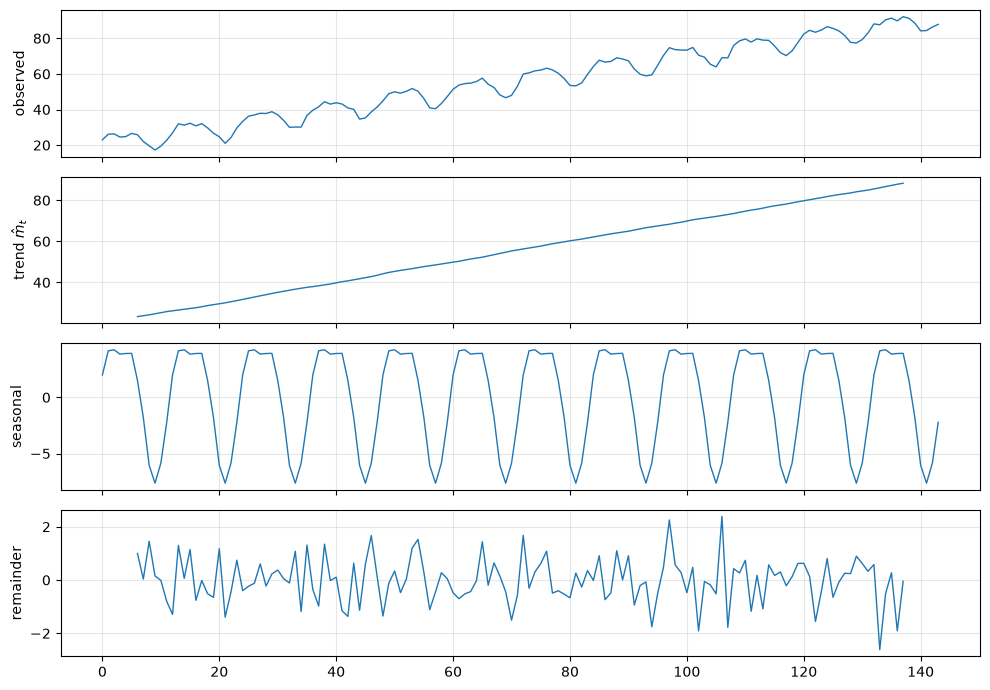

In [2]:
n, d = 144, 12
tt = np.arange(n)
seas_true = 6 * np.sin(2 * np.pi * tt / d) + 2 * np.cos(4 * np.pi * tt / d)
seas_true = seas_true - seas_true[:d].mean()
x = 20 + 0.5 * tt + seas_true + rng.normal(0, 1.0, n)

# centred moving average for even period d = 2q: half weights at ends
q = d // 2
w = np.r_[0.5, np.ones(d - 1), 0.5] / d
m_hat = np.full(n, np.nan)
for i in range(q, n - q):
    m_hat[i] = np.dot(w, x[i - q:i + q + 1])

Y = x - m_hat
w_k = np.array([np.nanmean(Y[k::d]) for k in range(d)])
s_hat = w_k - w_k.mean()
S = np.tile(s_hat, n // d)
R = x - m_hat - S

print("sum of seasonal indices  :", round(s_hat.sum(), 10))
print("max |s_hat - s_true|     :", np.abs(s_hat - seas_true[:d]).max().round(3))
print("remainder sd (noise sd 1):", np.nanstd(R).round(3))

sd = seasonal_decompose(x, model="additive", period=d)
print("matches statsmodels      :", np.allclose(sd.seasonal[:d], s_hat), np.allclose(sd.trend[q:-q], m_hat[q:-q]))

fig, ax = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for a, (v, name) in zip(ax, [(x, "observed"), (m_hat, "trend $\\hat m_t$"), (S, "seasonal"), (R, "remainder")]):
    a.plot(v, lw=1); a.set_ylabel(name)
plt.tight_layout(); plt.show()

The estimated seasonal indices sum to zero and are close to the true pattern, the remainder has spread near the noise level, and the hand calculation agrees with `seasonal_decompose`. The trend is undefined for the first and last $d/2=6$ points: a centred smoother needs observations on both sides, which is why it is not a real-time tool at the sample boundary.

## Differencing as an alternative

For $X_t=m_t+S_t+Y_t$ with exactly repeating $S_t$, $\nabla_{12}X_t=(m_t-m_{t-12})+(Y_t-Y_{t-12})$. A linear trend then becomes a constant $12b$, and one further ordinary difference removes it.

slope b = 0.5, so 12b = 6.0
mean of seasonal difference : 5.94
mean of combined difference : 0.007
combined = x_t-x_{t-1}-x_{t-12}+x_{t-13}: True
usable sample sizes         : 144 143 132 131


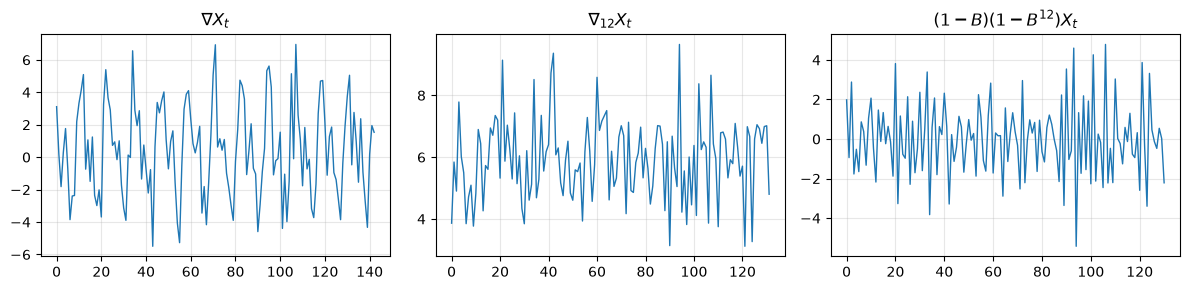

In [3]:
d1 = np.diff(x)                    # (1-B)
d12 = x[d:] - x[:-d]               # (1-B^12)
d1_12 = d12[1:] - d12[:-1]         # (1-B)(1-B^12)
direct = x[d + 1:] - x[d:-1] - x[1:-d] + x[:-d - 1]

print("slope b = 0.5, so 12b =", 12 * 0.5)
print("mean of seasonal difference :", d12.mean().round(2))
print("mean of combined difference :", d1_12.mean().round(3))
print("combined = x_t-x_{t-1}-x_{t-12}+x_{t-13}:", np.allclose(d1_12, direct))
print("usable sample sizes         :", len(x), len(d1), len(d12), len(d1_12))

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, (v, name) in zip(ax, [(d1, "$\\nabla X_t$"), (d12, "$\\nabla_{12}X_t$"), (d1_12, "$(1-B)(1-B^{12})X_t$")]):
    a.plot(v, lw=1); a.set_title(name)
plt.tight_layout(); plt.show()

Ordinary differencing leaves a seasonal wave; seasonal differencing removes the wave but leaves the constant $12b=6$; combining both gives a series centred near zero. Each difference shortens the sample (and doubles the noise variance), so use the smallest order that works.

## Multiplicative seasonality and the log transform

When the seasonal swing grows with the level, additive decomposition leaves a remainder with changing spread; taking logs makes the structure additive.

multiplicative factors mean : 1.0
remainder sd, first vs last 3 years (additive): 14.83 22.11
remainder sd, first vs last 3 years (log)     : 0.02 0.019
log-seasonal indices sum   : -0.0


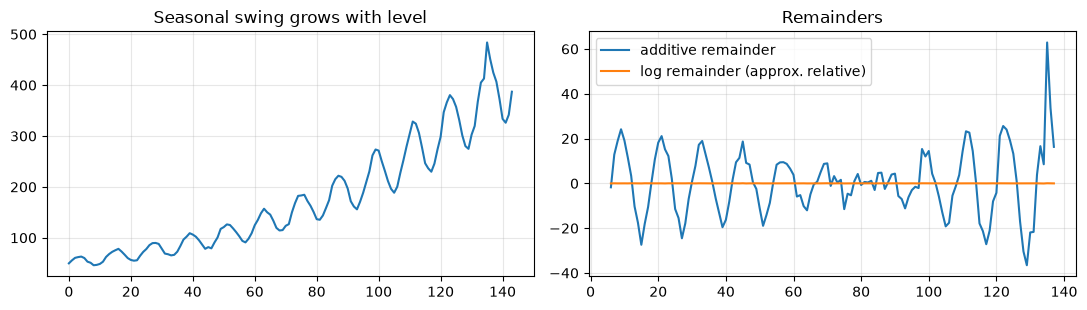

In [4]:
level = 50 * np.exp(0.015 * tt)
fac = 1 + 0.2 * np.sin(2 * np.pi * tt / d)
xm = level * fac * np.exp(rng.normal(0, 0.02, n))

add = seasonal_decompose(xm, model="additive", period=d)
mul = seasonal_decompose(xm, model="multiplicative", period=d)
lg = seasonal_decompose(np.log(xm), model="additive", period=d)

fac_hat = mul.seasonal[:d]
print("multiplicative factors mean :", fac_hat.mean().round(4))
print("remainder sd, first vs last 3 years (additive):",
      np.nanstd(add.resid[:36]).round(2), np.nanstd(add.resid[-36:]).round(2))
print("remainder sd, first vs last 3 years (log)     :",
      np.nanstd(lg.resid[:36]).round(3), np.nanstd(lg.resid[-36:]).round(3))
print("log-seasonal indices sum   :", lg.seasonal[:d].sum().round(8))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(xm); ax[0].set_title("Seasonal swing grows with level")
ax[1].plot(add.resid, label="additive remainder")
ax[1].plot(np.exp(lg.resid) - 1, label="log remainder (approx. relative)")
ax[1].legend(); ax[1].set_title("Remainders")
plt.tight_layout(); plt.show()

The multiplicative factors average 1 (the normalization convention), the additive remainder fans out as the level rises, and the log-scale remainder has roughly constant spread. A log or Box-Cox transform is therefore the usual fix before an additive method such as STL.

## Seasonal-naive benchmark

The seasonal-naive forecast repeats the value from the same season last year. We compare it with a naive (last value) forecast and with a seasonal-naive forecast plus average yearly drift on a 24-month hold-out of the additive series.

MAE naive          : 7.87
MAE seasonal naive : 8.99
MAE seasonal naive + drift (5.93/yr): 1.01
seasonal naive error at horizons 1, 3, 6, 12: [6.43 3.75 6.59 5.39]


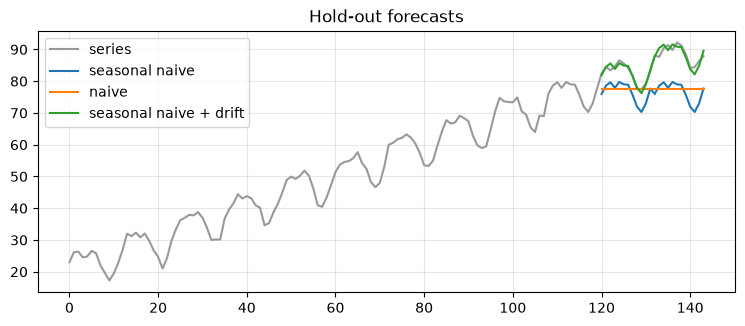

In [5]:
train, test = x[:-24], x[-24:]
h = np.arange(1, 25)
snaive = train[-d:][(h - 1) % d]
naive = np.full(24, train[-1])
yearly_change = np.mean(train[d:] - train[:-d])          # average seasonal difference
sn_drift = snaive + yearly_change * np.ceil(h / d)

def mae(f): return np.mean(np.abs(test - f))
print(f"MAE naive          : {mae(naive):.2f}")
print(f"MAE seasonal naive : {mae(snaive):.2f}")
print(f"MAE seasonal naive + drift ({yearly_change:.2f}/yr): {mae(sn_drift):.2f}")
print("seasonal naive error at horizons 1, 3, 6, 12:", np.abs(test - snaive)[[0, 2, 5, 11]].round(2))

plt.figure(figsize=(9, 3.4))
plt.plot(np.arange(len(x)), x, color="0.6", label="series")
plt.plot(np.arange(len(train), len(x)), snaive, label="seasonal naive")
plt.plot(np.arange(len(train), len(x)), naive, label="naive")
plt.plot(np.arange(len(train), len(x)), sn_drift, label="seasonal naive + drift")
plt.legend(); plt.title("Hold-out forecasts"); plt.show()

With a steep trend (about 6 units per year, comparable to the seasonal amplitude) plain seasonal naive is not better than the flat naive forecast: it repeats last year's season but misses the yearly level shift. Adding the average yearly change fixes this and is clearly best, and the large gain from one extra term shows why a benchmark should match the structure in the data. Any richer seasonal model should be compared with such benchmarks on future-like data.